
# ICS 438 – A4 · Task 1
**K-Means on 2D vs High-D**

**Your goals**
- Implement & run **K-Means** (scikit-learn allowed) on:
  - 2D subset (scatter plot with centroids)
  - High-D subset (visualize with **t-SNE**; do **not** cluster in t-SNE space)
- Justify choice of **K** and discuss differences between 2D and High-D.


In [47]:
# --- Setup & data ---
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

%matplotlib inline

df = pd.read_csv('Cust_Segmentation.csv')
df.head()


,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,Address,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,NBA001,6.3
1,2,47,1,26,100,4.582,8.218,0.0,NBA021,12.8
2,3,33,2,10,57,6.111,5.802,1.0,NBA013,20.9
3,4,29,2,4,19,0.681,0.516,0.0,NBA009,6.3
4,5,47,1,31,253,9.308,8.908,0.0,NBA008,7.2



## Part A — 2D K-Means (scatter)
1. Select **two numeric** features (e.g., `Income` & `DebtIncomeRatio`).
2. **Standardize** them.
3. Try **K ∈ {2,3,4,5,6}** (loop) and pick a final K (explain).
4. Plot 2D scatter colored by cluster; mark **centroids**.


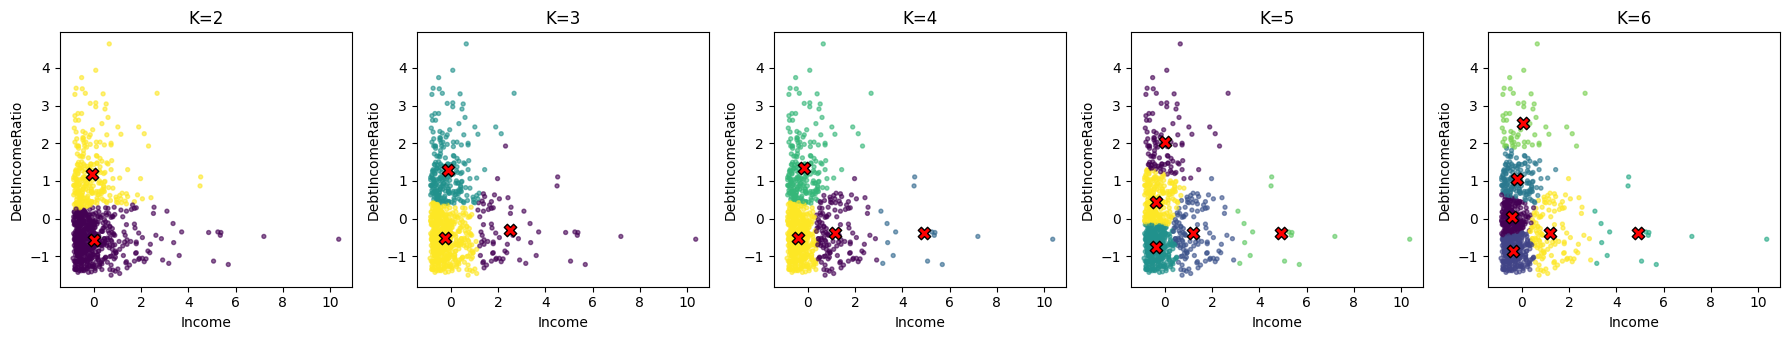

In [48]:
features_2d = ['Income', 'DebtIncomeRatio']
X2 = df[features_2d].dropna().to_numpy()

scaler2 = StandardScaler()
X2s = scaler2.fit_transform(X2)

ks = range(2, 7)

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))

for ax, k in zip(axes, ks):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X2s)

    ax.scatter(X2s[:, 0], X2s[:, 1], c=labels, s=8, alpha=0.6)
    centroidss = model.cluster_centers_
    ax.scatter(centroidss[:, 0], centroidss[:, 1], c='red', marker='X', s=80, edgecolors='k')
    ax.set_title(f'K={k}')
    ax.set_xlabel(features_2d[0])
    ax.set_ylabel(features_2d[1])

plt.tight_layout()
plt.show()

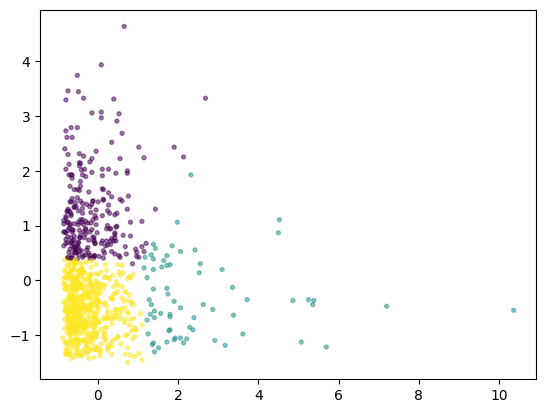

In [49]:

# --- TODO: choose your two features ---
features_2d = ['Income', 'DebtIncomeRatio']  # you may change
X2 = df[features_2d].dropna().to_numpy()

# Standardize
scaler2 = StandardScaler()
X2s = scaler2.fit_transform(X2)

# --- TODO: choose K (or loop over multiple K and select) ---
K = 2 # e.g., 3

model = KMeans(n_clusters=3)
labels = model.fit_predict(X2s)

# --- TODO: Create scatter with cluster colors and mark centroids ---
plt.scatter(X2s[:,0], X2s[:,1], c=labels, s=8, alpha=0.5)




## Part B — High-D K-Means (t‑SNE visualization)
1. Build **high‑dimensional X** from numeric columns (drop NaNs).
2. **Standardize**.
3. Run **K‑Means in High‑D** (use same K as Part A unless justified otherwise).
4. Reduce to 2D using **t‑SNE** (for viz only).
5. Plot t‑SNE scatter colored by **High‑D** cluster labels.


In [50]:
# --- High-D feature set ---
num_cols = ['Age','Edu','Years Employed','Income','Card Debt','Other Debt','DebtIncomeRatio']
X = df[num_cols].dropna().to_numpy()

scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# --- TODO: run KMeans in High-D ---


# --- TODO: t-SNE for viz only (do not cluster in t-SNE space) ---


# --- TODO: scatter colored by 'labels' ---




## Part C — Short write‑up (≤ 200 words)
- How did you choose **K**?
- Differences between 2D and High‑D clustering?
- Any preprocessing/outlier handling that mattered?



# ICS 438 – A4 · Task 2 
**Clustering non‑spherical 2D data, then high‑D data**

> You must choose a suitable algorithm (do **not** assume a centroid-based method will work). You will:
> 1) cluster a crescent‑shaped **2D** dataset, 2) study parameter effects, 3) apply the **same algorithm** to **high‑D** blobs and analyze efficiency/behavior.


In [51]:
# --- Setup (no specific clustering algorithm imported here) ---
import numpy as np, matplotlib.pyplot as plt
from time import perf_counter
from sklearn.datasets import make_moons, make_blobs
from sklearn.preprocessing import StandardScaler

%matplotlib inline



## Part A — 2D crescent dataset (moons)
1. Generate 2D moons: `make_moons(n_samples=1000, noise=0.05, random_state=42)`.
2. **Standardize** features.
3. **Choose an algorithm** that can separate non‑spherical shapes.
4. Fit it, visualize clusters, and **justify** your choice (and why centroid‑based methods struggle).


In [52]:
# --- Generate moons & scale ---
X2, y2_true = make_moons(n_samples=1000, noise=0.05, random_state=42)
Xs2 = StandardScaler().fit_transform(X2)

# --- TODO: Choose & import your algorithm below (e.g., density-based) ---
# from sklearn.cluster import ...

# --- TODO: instantiate with parameters (e.g., neighborhood size, minimum core points)
# model2 = ...

# --- TODO: Fit & predict on Xs2 ---


# --- TODO: visualize ---




## Part B — Parameter exploration
Pick **2–3** values for the key parameters of your chosen algorithm (e.g., neighborhood size, minimum points).  
For each setting, refit, visualize, and record: runtime, number of clusters.


In [53]:
# --- TODO: Parameter sweep template ---
# You can adapt the following template to your chosen algorithm

# --- Define parameter ranges ---
# param1_list = [...] # 2–3 values
# param2_list = [...] # 2–3 values

# --- Loop over parameters ---
# for p1 in param1_list:
#     for p2 in param2_list:
#         t0 = perf_counter()
#         model = ... # your algorithm with (p1, p2)
#         labels = model.fit_predict(Xs2)
#         t1 = perf_counter()

# --- Record stats ---
#         n_clusters = len(set(labels)) - (1 if -1 in labels else 0)


# --- Print & visualize ---
#         print(f"params=({p1},{p2}) time={t1-t0:.4f}s clusters={n_clusters} noise={n_noise}")
#         plt.figure(figsize=(6,5))
#         plt.scatter(Xs2[:,0], Xs2[:,1], c=labels, s=10, alpha=0.9)
#         plt.title(f"Moons: params=({p1},{p2})"); plt.show()



## Part C — High‑D data
1. Generate high‑D blobs: `make_blobs(n_samples=6000, centers=4, n_features=20, cluster_std=2.0, random_state=7)`.
2. Scale features.
3. Use the **same algorithm & parameters** from Part A (or justify changes).
4. Measure **runtime** and summarize **efficiency**.
5. Discuss **cluster separability** and **parameter sensitivity** in high‑D.


In [54]:
# --- High-D blobs & scaling ---
Xh, yh_true = make_blobs(n_samples=6000, centers=4, n_features=20, cluster_std=2.0, random_state=7)
Xh_s = StandardScaler().fit_transform(Xh)

# --- TODO: Use the SAME algorithm & parameters (or justify changes) ---
# t0 = perf_counter()
# model_h = ...
# labels_h = model_h.fit_predict(Xh_s)
# t1 = perf_counter()

# n_clusters_h = len(set(labels_h)) - (1 if -1 in labels_h else 0)


# print(f"[High-D] time={t1-t0:.4f}s clusters={n_clusters_h} noise={n_noise_h}")

# --- TODO: quick PCA for visualization only (do not cluster in reduced space) ---
from sklearn.decomposition import PCA




### Write‑up (≤ 250 words)
- Why your chosen algorithm works for moons; why centroid‑based methods struggle.
- Parameter effects you observed (and why).
- Differences in efficiency & separability in high‑D; mention the **curse of dimensionality**.


# ICS 438 — Assignment 4 (Task 3)
## Discrete Naive Bayes (Categorical) — Implementation from Scratch

**Goal:** Implement a **categorical Naive Bayes classifier** (Lec 14 style) and evaluate it on a **discrete dataset**.
You will write core parts yourself (counting, priors, conditionals with Laplace smoothing, prediction, and metrics).

### What you'll do
- Generate a **categorical dataset** (age, income, student, credit_rating → label)
- Implement **NaiveBayesDiscrete** from scratch
- Evaluate with **manual accuracy** and a **manual confusion matrix**
- Answer brief reflection questions

> **Rules:** No `sklearn` for metrics; use only `numpy`/`pandas`/`matplotlib`.


In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.precision', 3)

## Step 1 — Generate a *Discrete* Dataset

We will use four **categorical** features:
- `age` ∈ {`<=30`, `31-40`, `>40`}
- `income` ∈ {`low`, `medium`, `high`}
- `student` ∈ {`no`, `yes`}
- `credit_rating` ∈ {`fair`, `excellent`}



In [56]:
N = 600                  
SEED = 438              
rng = np.random.default_rng(SEED)

# Categorical vocabularies
AGES = ['<=30', '31-40', '>40']
INCOMES = ['low', 'medium', 'high']
STUDENTS = ['no', 'yes']
CREDITS = ['fair', 'excellent']

def sample_row(n=1, rng=rng):
    rows = []
    for _ in range(n):
        age = rng.choice(AGES,    p=[0.35, 0.35, 0.30])   # TODO: tweak probs if curious
        inc = rng.choice(INCOMES, p=[0.30, 0.50, 0.20])
        stu = rng.choice(STUDENTS,p=[0.45, 0.55])
        cre = rng.choice(CREDITS, p=[0.60, 0.40])

        # Signal for label (you can read, no need to edit):
        # more likely 'yes' if (31-40), student=yes, credit=fair; slightly less if income=high
        logit = 0.0
        if age == '31-40': logit += 0.7
        if age == '>40':   logit += 0.2
        if stu == 'yes':   logit += 0.6
        if cre == 'fair':  logit += 0.4
        if inc == 'high':  logit -= 0.2

        p_yes = 1 / (1 + np.exp(-logit))
        label = rng.choice(['yes','no'], p=[p_yes, 1-p_yes])
        rows.append((age, inc, stu, cre, label))
    return rows

data = sample_row(N, rng)
df = pd.DataFrame(data, columns=['age','income','student','credit_rating','label'])

print(df.shape)
df.head()


(600, 5)


,age,income,student,credit_rating,label
0,>40,medium,yes,excellent,no
1,>40,medium,yes,excellent,yes
2,<=30,medium,yes,excellent,yes
3,>40,high,yes,fair,yes
4,>40,medium,yes,excellent,yes


## Step 2 — Train/Test Split (Write It Yourself)

**Requirements:**
- Randomly shuffle the rows (use `rng`).
- Split into `train_df` (70%) and `test_df` (30%).
- Try to keep class balance roughly similar (OK if not perfect).

**Hint:** You can shuffle indices with `rng.permutation(len(df))`.


In [57]:
# === TODO: Implement your own shuffle & split (no sklearn) ===

# 1) Shuffle
# TODO: idx = ...

# 2) Compute split point
# TODO: split = ...

# 3) Build train_df and test_df
# TODO: train_df = df.iloc[...].reset_index(drop=True)
# TODO: test_df  = df.iloc[...].reset_index(drop=True)

# Quick checks (should not raise)
assert 'label' in df.columns, "Expected a 'label' column"
# print('Train/Test sizes:', train_df.shape, test_df.shape)
# print(train_df['label'].value_counts(), '\n', test_df['label'].value_counts())


## Step 3 — Helper Functions (Counting & Vocab)

Implement helper functions used by the classifier.

**TODOs:**
1. `collect_attr_values(train_df, label_col)` → dict: `attr -> set(values)`
2. `count_classes(train_df, label_col)` → dict: `class -> count`
3. `count_conditional(train_df, attrs, label_col)` → nested dict:
   `{class: {attr: {value: count}}}`


In [58]:
# === TODO: Implement helper functions ===

def collect_attr_values(train_df, label_col='label'):
    """
    Return: dict[str, set[str]]  # attr -> set_of_values
    """
    # TODO
    raise NotImplementedError

def count_classes(train_df, label_col='label'):
    """
    Return: dict[str, int]  # class_label -> count
    """
    # TODO
    raise NotImplementedError

def confusion_matrix_manual(y_true, y_pred, labels):
    """
    Return: list[list[int]] of shape (len(labels), len(labels))
    Rows: true labels (labels order), Cols: predicted labels
    """
    # TODO
    raise NotImplementedError

# === Simple self-checks (remove raises when done) ===
# av = collect_attr_values(df, 'label')
# cc = count_classes(df, 'label')
# cd = count_conditional(df, [a for a in df.columns if a!='label'], 'label')
# print(list(av.keys())[:3], list(cc.items())[:2])


## Step 4 — Implement `NaiveBayesDiscrete` (Categorical)

Implement a Lec-14 style Naive Bayes:
- Priors: `P(C) = |C| / |D|` (store **log priors**)
- Conditionals: `P(x_k=v | C)` with **Laplace smoothing** (add 1)
- Predict: Choose the class (c) that maximising the P(c | x)

**TODOs inside the class:** implement your own NaiveBayesCategorical class.


In [59]:
from collections import Counter, defaultdict
import numpy as np

class NaiveBayesCategorical:
    """
    Naive Bayes for categorical features only (no logs).
    Decision rule:
        Choose the class with the largest posterior P(c|x).
    """

    def __init__(self, alpha=1.0):
        # Laplace smoothing parameter (to avoid zero probability)
        self.alpha = float(alpha)

        # These variables will be filled after training
        self.classes_ = None          # e.g., ['yes', 'no']
        self.class_counts_ = None     # e.g., how many yes / how many no
        self.class_priors_ = None     # P(c) for each class

        # Categorical feature vocabularies and counts
        # vocab_[j] = all possible values seen in feature j
        self.vocab_ = defaultdict(set)
        # counts_[(j, c)] = Counter of values of feature j within class c
        self.counts_ = dict()
        
    # TODO: Finish the class with at least fit and predict methods below, you may add more helper methods


## Step 5 — Train Your Classifier

In [60]:
# === TODO: Instantiate and fit your model ===


# === TODO: Predict on test set ===




## Step 6 — Manual Metrics (No `sklearn`)

**Implement from scratch:**
- `accuracy_manual(y_true, y_pred)`
- `confusion_matrix_manual(y_true, y_pred, labels)` → returns nested list `[[...]]`

**Then:** pretty-print the confusion matrix with row/col labels.


In [61]:
# === TODO: Implement manual metrics ===

def accuracy_manual(y_true, y_pred):
    # TODO: compute fraction of correct predictions
    raise NotImplementedError

def confusion_matrix_manual(y_true, y_pred, labels):
    # TODO: build nested list cm[true_idx][pred_idx]
    raise NotImplementedError

def print_confusion_matrix(cm, labels):
    # Nicely formatted confusion matrix (rows=true, cols=pred)
    print('Confusion Matrix (rows = true, cols = predicted)\n')
    header = ' ' * 12 + '  '.join(f"{c:>8}" for c in labels)
    print(header)
    for i, lab in enumerate(labels):
        row = '  '.join(f"{cm[i][j]:>8}" for j in range(len(labels)))
        print(f"{lab:>8}  {row}")

# === TODO: Use your functions ===
# y_true = test_df['label'].values
# acc = accuracy_manual(y_true, y_pred)
# cm  = confusion_matrix_manual(y_true, y_pred, labels=nb_clf.classes_)

# print(f'Accuracy (manual): {acc:.3f}\n')
# print_confusion_matrix(cm, nb_clf.classes_)


### Short Reflection (2–4 sentences)

**Prompt:** In your own words, justify why implementing a **categorical Naive Bayes** was appropriate for this Step.
Touch on **data type**, **simplicity/interpretability**, **efficiency**, and **smoothing**.


# Task 4 — Real-World Classification on Churn Data (Logistic Regression vs *Your* Naive Bayes)

**Goal:** Compare two models on the same churn dataset:
1. **Logistic Regression** on the original (numeric + binary) features  
2. **Your own categorical Naive Bayes** on a *categorised* (binned) version of the dataset

---

### 4.1 Load the dataset
Load the churn dataset and split into train and test df.

In [62]:
# 4.1a Load dataset and split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_raw = pd.read_csv('ChurnData.csv')
print(df_raw.shape)
df_raw.head(3)

# 4.1b Train/Test split (no sklearn)
SEED = 438
rng = np.random.default_rng(SEED)

df_raw['label'] = df_raw['churn'].map({0:'no', 1:'yes'})

# Split the dataset into train and test dataset

idx = rng.permutation(len(df_raw))
split = int(0.7 * len(df_raw))
train_df = df_raw.iloc[idx[:split]].reset_index(drop=True)
test_df  = df_raw.iloc[idx[split:]].reset_index(drop=True)

print("Train/Test sizes:", train_df.shape, test_df.shape)
print("Train label balance:\n", train_df['label'].value_counts(normalize=True))
print("Test  label balance:\n", test_df['label'].value_counts(normalize=True))

(200, 28)
Train/Test sizes: (140, 29) (60, 29)
Train label balance:
 label
no     0.736
yes    0.264
Name: proportion, dtype: float64
Test  label balance:
 label
no     0.65
yes    0.35
Name: proportion, dtype: float64


### 4.2 Train **Logistic Regression** (before any categorical processing)
Train Logistic Regression using the **original dataset** (numeric + binary features).
This reflects how LR is typically used in practice.

> Take care because you need to categorise all the features you chosen here later to fit the Naive Bayes class you have implemented.

In [63]:
# 4.2 Logistic Regression (sklearn) on chosen features

from sklearn.linear_model import LogisticRegression

# TODO: Train the logistic regression and make prediction

FEATURES = [] # Choose the features you want to use
df_lr_train = train_df[FEATURES + ['label']]
df_lr_test  = test_df[FEATURES + ['label']]

# TODO: Predict on test set
pred_lr = None  # Change this to your predictions

### 4.3 Preprocess the dataset into *categorical form*
Now convert the dataset into **categorical-only** so that it is suitable for your Naive Bayes.

One example will be provided (in code):  
- `age` → bins (`<=30`, `31–50`, `>50`)

Your TODOs are transferring the FEATURES into categorical features by follwing steps:
- Bin all the **numerical** features into categories  (as provided example)
- Convert all binary `0/1` features → `"no"` / `"yes"`  
- Convert the **label** into `"yes"` / `"no"`  
- Ensure the final dataset contains **categorical values only**

You will train Naive Bayes on this processed dataset. (DONT forget to split the dataset into train and test df!)

In [64]:
## Part 4.3 Data preprocessing

df_nb = df_raw.copy()

# ✅ Example: bin 'age' into three categories
#    Labels align with our categorical NB style from Task 3
df_nb['age_cat'] = pd.cut(
    df_nb['age'],
    bins=[-np.inf, 30, 50, np.inf],
    labels=['<=30', '31-50', '>50']
)

# TODO-1: bin other numeric features into categories (e.g., for income you can bin them into low/mid/high).

# TODO-2: map binary 0/1 columns (e.g., 'internet','wireless','pager') to 'no'/'yes'

# TODO-3: convert the label to 'yes'/'no'

# TODO-4: choose which categorical features you will use for Naive Bayes

NB_FEATURES = ['age_cat']  # TODO: only the example; expand after you do TODOs

assert len(NB_FEATURES) == len(FEATURES), "NB_FEATURES must match FEATURES after preprocessing."

# After you have finished the categorical feature preprocessing, create train/test splits for NB

idx = rng.permutation(len(df_raw))
split = int(0.7 * len(df_raw))
train_df_nb = df_nb.iloc[idx[:split]].reset_index(drop=True)
test_df_nb  = df_nb.iloc[idx[split:]].reset_index(drop=True)

AssertionError: NB_FEATURES must match FEATURES after preprocessing.

### 4.4 Train **your Naive Bayes** (from Task 3)
Use the categorised dataset from Step 4.3.  
This represents the **discrete probability** modelling approach.

In [ ]:
# 4.4 Train YOUR Naive Bayes (categorical) from Task 3
# Assumes your class is already defined in Task 3 cells:
# class NaiveBayesDiscrete: ...

# TODO: Finish the training and prediction


# TODO: Predict on test


# TODO: Keep y_true as strings 'yes'/'no' for manual metrics
pred_nb = None  # Change this to your predictions

### 4.5 Manually compute evaluation metrics
For **both models**, manually compute:
- Accuracy
- Sensitivity (Recall of positive class)
- Specificity
- Precision
- Recall
- F1-score

(*Implement from scratch using the confusion matrix – no sklearn.metrics*)


In [ ]:
# 4.5 Manual metrics (for both models, no sklearn)
# You may use the code implemented previously in task 3.

def confusion_matrix_manual(y_true, y_pred, labels):
    # TODO: Finish the confusion matrix
    pass

def metrics_from_cm(cm):
    # TODO: Implement the metrics calculation below
    pass


    # return {
    #     'accuracy': accuracy,
    #     'sensitivity': sensitivity,
    #     'specificity': specificity,
    #     'precision': precision,
    #     'recall': recall,
    #     'f1': f1
    # }

def print_metrics(name, cm, m):
    print(f"=== {name} ===")
    print("Confusion Matrix (rows=true , cols=pred):")
    print(np.array(cm))
    for k,v in m.items():
        print(f"{k:>12}: {v:.3f}")
    print()

# NB metrics
# TODO: Calculate the metrics

# LR metrics
# TODO: Calculate the metrics

# TODO: Print the final metrics using the given print_metrics function
# print_metrics("Naive Bayes (Your Impl.)", cm_nb, m_nb)
# print_metrics("Logistic Regression",      cm_lr, m_lr)

### 4.7 Compare & Reflect (2–3 sentences)
Briefly comment:
- Which model performed better?
- Why might Logistic Regression and Naive Bayes differ?
- Does categorising continuous variables help or hurt performance?